In [26]:
import tensorflow as tf
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import matplotlib.pyplot as plt

# Dataset properties
data_dir = "TrainData"
img_size = 128
num_classes = 62 # 10 numbers + 26 uppercase + 26 lowercase
characters = list('0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz')
label_to_char_map = {i: char for i, char in enumerate(characters)}

seed = 1234
batch_size = 32
epochs = 15

train_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=(img_size, img_size),
    batch_size=batch_size,
    label_mode='int'
)

val_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=(img_size, img_size),
    batch_size=batch_size,
    label_mode='int'
)

train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

Found 53172 files belonging to 62 classes.
Using 42538 files for training.
Found 53172 files belonging to 62 classes.
Using 10634 files for validation.


In [23]:
inputs = keras.Input(shape=(img_size, img_size, 3))

x = layers.Rescaling(1./255)(inputs)

x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Flatten()(x)

x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(num_classes, activation='softmax')(x)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 62)             │         7,998 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,295,678 (16.39 MB)

 Trainable params: 4,295,678 (16.39 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/15
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 365s 273ms/step - accuracy: 0.6150 - loss: 1.3755 - val_accuracy: 0.8493 - val_loss: 0.4360
Epoch 2/15
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 302s 227ms/step - accuracy: 0.7764 - loss: 0.6575 - val_accuracy: 0.8682 - val_loss: 0.3448
Epoch 3/15
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 321s 241ms/step - accuracy: 0.8136 - loss: 0.5190 - val_accuracy: 0.8837 - val_loss: 0.2956
Epoch 4/15
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 302s 227ms/step - accuracy: 0.8350 - loss: 0.4417 - val_accuracy: 0.8969 - val_loss: 0.2694
Epoch 5/15
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 471s 354ms/step - accuracy: 0.8514 - loss: 0.3921 - val_accuracy: 0.8993 - val_loss: 0.2514
Epoch 6/15
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 320s 241ms/step - accuracy: 0.8647 - loss: 0.3553 - val_accuracy: 0.9050 - val_loss: 0.2443
Epoch 7/15
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 303s 228ms/step - accuracy: 0.8752 - loss: 0.3257 - val_accuracy: 0.9109 - val_loss: 0.2245
Epoch 8/15
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 304s 228ms/step - ac

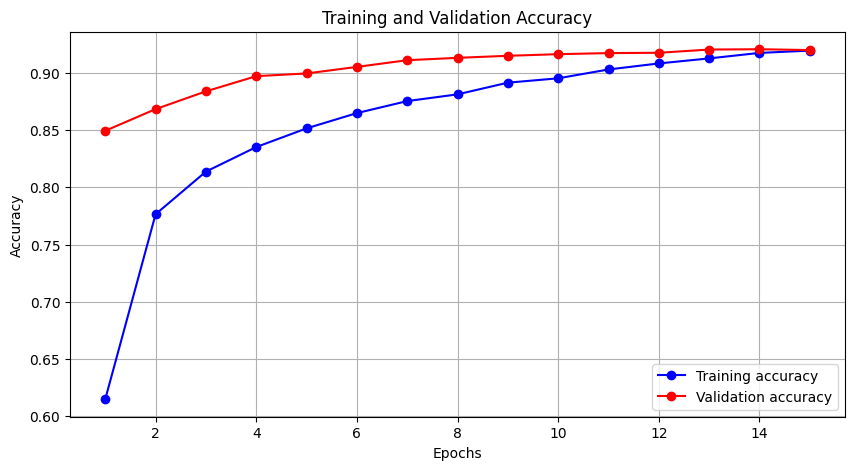

In [27]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs_list = range(1, len(acc) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_list, acc, 'bo-', label='Training accuracy')
plt.plot(epochs_list, val_acc, 'ro-', label='Validation accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

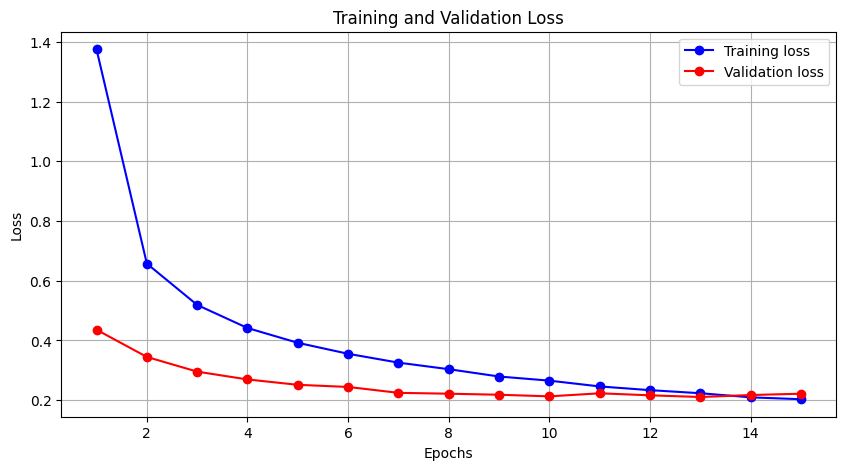

In [28]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(10, 5))
plt.plot(epochs_list, loss, 'bo-', label='Training loss')
plt.plot(epochs_list, val_loss, 'ro-', label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()